In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')
 
sns.set_theme(style="whitegrid")
plt.rcParams.update({'figure.dpi': 120, 'font.family': 'Arial'})
 
print("Libraries loaded.")

Libraries loaded.


In [2]:
# Re-use the cleaned data from Task 1
# If running fresh, reload and re-clean here
transactions = pd.read_excel("QVI_transaction_data.xlsx")
behaviour     = pd.read_csv("QVI_purchase_behaviour.csv")
 
# Fix date
transactions['DATE'] = pd.to_datetime(
    transactions['DATE'], origin='1899-12-30', unit='D')
 
# Remove salsa
transactions = transactions[
    ~transactions['PROD_NAME'].str.upper().str.contains('SALSA')].copy()
 
# Remove outlier customers (buying 200 units)
high_qty_cards = transactions[transactions['PROD_QTY'] > 100]['LYLTY_CARD_NBR'].unique()
transactions = transactions[
    ~transactions['LYLTY_CARD_NBR'].isin(high_qty_cards)].copy()
 
# Merge with behaviour
data = transactions.merge(behaviour, on='LYLTY_CARD_NBR', how='left')
data.dropna(subset=['LIFESTAGE', 'PREMIUM_CUSTOMER'], inplace=True)
 
print("Data ready. Shape:", data.shape)
print("Date range:", data['DATE'].min(), "→", data['DATE'].max())

Data ready. Shape: (246740, 10)
Date range: 2018-07-01 00:00:00 → 2019-06-30 00:00:00


In [3]:
TRIAL_STORES   = [77, 86, 88]
 
# Trial ran Feb–Apr 2019
TRIAL_START    = pd.Timestamp('2019-02-01')
TRIAL_END      = pd.Timestamp('2019-04-30')
 
# Pre-trial period for control matching: Jul 2018 – Jan 2019
PRETRIAL_START = pd.Timestamp('2018-07-01')
PRETRIAL_END   = pd.Timestamp('2019-01-31')
 
print(f"Trial stores : {TRIAL_STORES}")
print(f"Trial period : {TRIAL_START.date()} → {TRIAL_END.date()}")
print(f"Pre-trial    : {PRETRIAL_START.date()} → {PRETRIAL_END.date()}")
 

Trial stores : [77, 86, 88]
Trial period : 2019-02-01 → 2019-04-30
Pre-trial    : 2018-07-01 → 2019-01-31


In [4]:
data['MONTH'] = data['DATE'].dt.to_period('M')
 
store_monthly = (
    data.groupby(['STORE_NBR', 'MONTH'])
    .agg(
        tot_sales    = ('TOT_SALES',      'sum'),
        num_customers= ('LYLTY_CARD_NBR', 'nunique'),
        num_txns     = ('TXN_ID',         'nunique'),
    )
    .reset_index()
)
 
store_monthly['avg_spend_per_txn'] = (
    store_monthly['tot_sales'] / store_monthly['num_txns']).round(4)
 
store_monthly['MONTH_DT'] = store_monthly['MONTH'].dt.to_timestamp()
 
print("Store monthly metrics shape:", store_monthly.shape)
print(store_monthly.head())

Store monthly metrics shape: (3165, 7)
   STORE_NBR    MONTH  tot_sales  num_customers  num_txns  avg_spend_per_txn  \
0          1  2018-07      188.9             47        49             3.8551   
1          1  2018-08      168.4             41        41             4.1073   
2          1  2018-09      268.1             57        59             4.5441   
3          1  2018-10      175.4             39        40             4.3850   
4          1  2018-11      184.8             44        45             4.1067   

    MONTH_DT  
0 2018-07-01  
1 2018-08-01  
2 2018-09-01  
3 2018-10-01  
4 2018-11-01  


In [5]:
# We match on pre-trial period using:
#   1. Pearson correlation of monthly total sales
#   2. Magnitude distance of monthly total sales
# Combined score → lowest = best control store
 
def get_pretrial(store_monthly, store_nbr, metric='tot_sales'):
    """Return monthly metric series for a store during pre-trial."""
    mask = (
        (store_monthly['STORE_NBR'] == store_nbr) &
        (store_monthly['MONTH_DT'] >= PRETRIAL_START) &
        (store_monthly['MONTH_DT'] <= PRETRIAL_END)
    )
    return store_monthly.loc[mask, ['MONTH', metric]].set_index('MONTH')[metric]
 
 
def magnitude_distance(s1, s2):
    """Normalised magnitude distance — 0 = identical, 1 = maximally different."""
    idx = s1.index.intersection(s2.index)
    if len(idx) == 0:
        return 1.0
    a, b = s1[idx].values, s2[idx].values
    denom = max(a.max(), b.max()) - min(a.min(), b.min())
    if denom == 0:
        return 0.0
    dist = np.abs(a - b).mean() / denom
    # Convert to similarity (1 = identical)
    return 1 - dist
 
 
def find_control_store(trial_store, store_monthly, metric='tot_sales'):
    """
    Find the best control store for a given trial store.
    Returns a DataFrame of all candidate stores ranked by combined score.
    """
    trial_series = get_pretrial(store_monthly, trial_store, metric)
    
    all_stores = store_monthly['STORE_NBR'].unique()
    # Exclude the three trial stores from candidates
    candidates  = [s for s in all_stores if s not in TRIAL_STORES]
    
    results = []
    for store in candidates:
        cand_series = get_pretrial(store_monthly, store, metric)
        idx = trial_series.index.intersection(cand_series.index)
        if len(idx) < 4:          # need at least 4 overlapping months
            continue
        
        corr = trial_series[idx].corr(cand_series[idx])
        mag  = magnitude_distance(trial_series[idx], cand_series[idx])
        
        # Combined score: average of correlation and magnitude similarity
        # Both on 0-1 scale, higher = better match
        combined = (corr + mag) / 2
        
        results.append({
            'candidate_store': store,
            'correlation':     round(corr, 4),
            'magnitude_sim':   round(mag, 4),
            'combined_score':  round(combined, 4),
        })
    
    return (pd.DataFrame(results)
            .sort_values('combined_score', ascending=False)
            .reset_index(drop=True))
 

In [6]:
control_map = {}
 
for trial in TRIAL_STORES:
    print(f"\n{'='*55}")
    print(f"  Trial Store {trial} — Top 5 Control Candidates")
    print(f"{'='*55}")
    ranking = find_control_store(trial, store_monthly, metric='tot_sales')
    print(ranking.head(5).to_string(index=False))
    best = ranking.iloc[0]['candidate_store']
    control_map[trial] = int(best)
    print(f"\n  >>> Best control store for Store {trial}: Store {best}")
 
print(f"\n\nFINAL CONTROL STORE MAPPING:")
for k, v in control_map.items():
    print(f"  Trial Store {k}  →  Control Store {v}")


  Trial Store 77 — Top 5 Control Candidates
 candidate_store  correlation  magnitude_sim  combined_score
             233       0.9736         0.8561          0.9149
              50       0.8977         0.7434          0.8206
              53       0.6365         0.7637          0.7001
             167       0.6547         0.6503          0.6525
             188       0.5425         0.7575          0.6500

  >>> Best control store for Store 77: Store 233.0

  Trial Store 86 — Top 5 Control Candidates
 candidate_store  correlation  magnitude_sim  combined_score
             155       0.8695         0.8497          0.8596
             138       0.7961         0.8252          0.8106
             114       0.7509         0.8238          0.7874
             269       0.7474         0.7791          0.7633
             106       0.6821         0.7887          0.7354

  >>> Best control store for Store 86: Store 155.0

  Trial Store 88 — Top 5 Control Candidates
 candidate_store  correlation

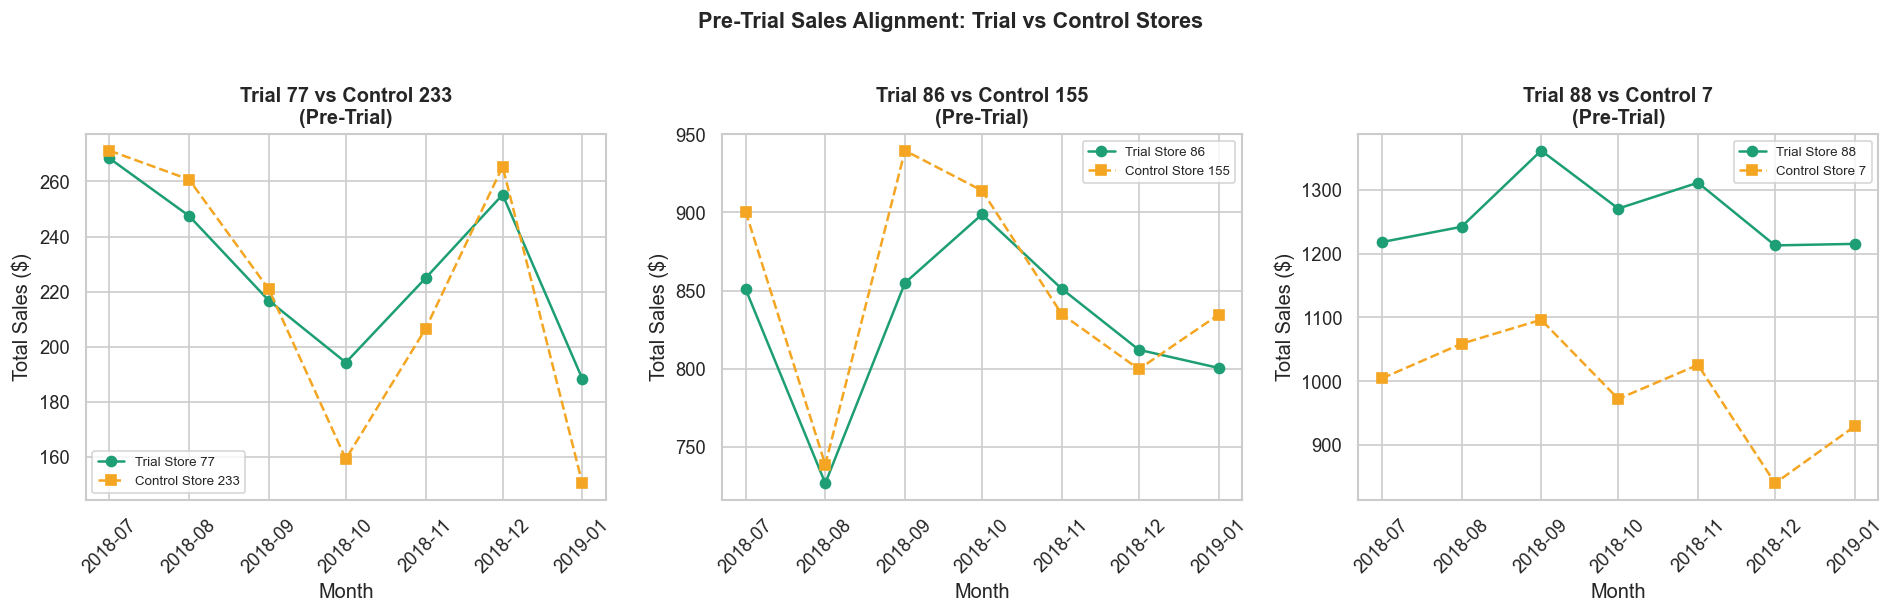

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
 
for ax, trial in zip(axes, TRIAL_STORES):
    control = control_map[trial]
    
    t_data = store_monthly[
        (store_monthly['STORE_NBR'] == trial) &
        (store_monthly['MONTH_DT'] <= PRETRIAL_END)
    ].sort_values('MONTH_DT')
    
    c_data = store_monthly[
        (store_monthly['STORE_NBR'] == control) &
        (store_monthly['MONTH_DT'] <= PRETRIAL_END)
    ].sort_values('MONTH_DT')
    
    ax.plot(t_data['MONTH_DT'], t_data['tot_sales'],
            color='#1D9E75', marker='o', label=f'Trial Store {trial}')
    ax.plot(c_data['MONTH_DT'], c_data['tot_sales'],
            color='#F4A623', marker='s', linestyle='--',
            label=f'Control Store {control}')
    ax.set_title(f'Trial {trial} vs Control {control}\n(Pre-Trial)', fontweight='bold')
    ax.set_xlabel('Month')
    ax.set_ylabel('Total Sales ($)')
    ax.tick_params(axis='x', rotation=45)
    ax.legend(fontsize=8)
 
plt.suptitle('Pre-Trial Sales Alignment: Trial vs Control Stores',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('plot_pretrial_alignment.png', bbox_inches='tight')
plt.show()
 

In [14]:
# ── CELL 8: Trial Performance Function (FIXED v2) ────────────
def assess_trial(trial_store, control_store, store_monthly, metric='tot_sales'):
    t = store_monthly[store_monthly['STORE_NBR'] == trial_store].copy()
    c = store_monthly[store_monthly['STORE_NBR'] == control_store].copy()

    # Scale control to trial's pre-trial average
    t_pretrial = t[t['MONTH_DT'] <= PRETRIAL_END][metric].mean()
    c_pretrial = c[c['MONTH_DT'] <= PRETRIAL_END][metric].mean()
    scale = t_pretrial / c_pretrial if c_pretrial != 0 else 1

    # Rename before merging — no 'period' column yet
    t = t[['MONTH', 'MONTH_DT', metric]].rename(
        columns={metric: metric + '_trial'})

    c['scaled'] = c[metric] * scale
    c = c[['MONTH', 'MONTH_DT', 'scaled']].rename(
        columns={'scaled': metric + '_control_scaled'})

    merged = t.merge(c, on=['MONTH', 'MONTH_DT'])

    # Add period column AFTER merge
    merged['period'] = merged['MONTH_DT'].apply(
        lambda d: 'Trial' if TRIAL_START <= d <= TRIAL_END else 'Pre-Trial'
    )
    return merged, scale
 

In [15]:
# ── CELL 9: Statistical Significance Test (FIXED) ────────────
def t_test_trial(merged_df, metric='tot_sales'):
    trial_period = merged_df[merged_df['period'] == 'Trial']

    trial_vals   = trial_period[metric + '_trial'].values
    control_vals = trial_period[metric + '_control_scaled'].values

    if len(trial_vals) < 2:
        return None, None

    t_stat, p_val = stats.ttest_rel(trial_vals, control_vals)
    return round(t_stat, 4), round(p_val, 4)
 

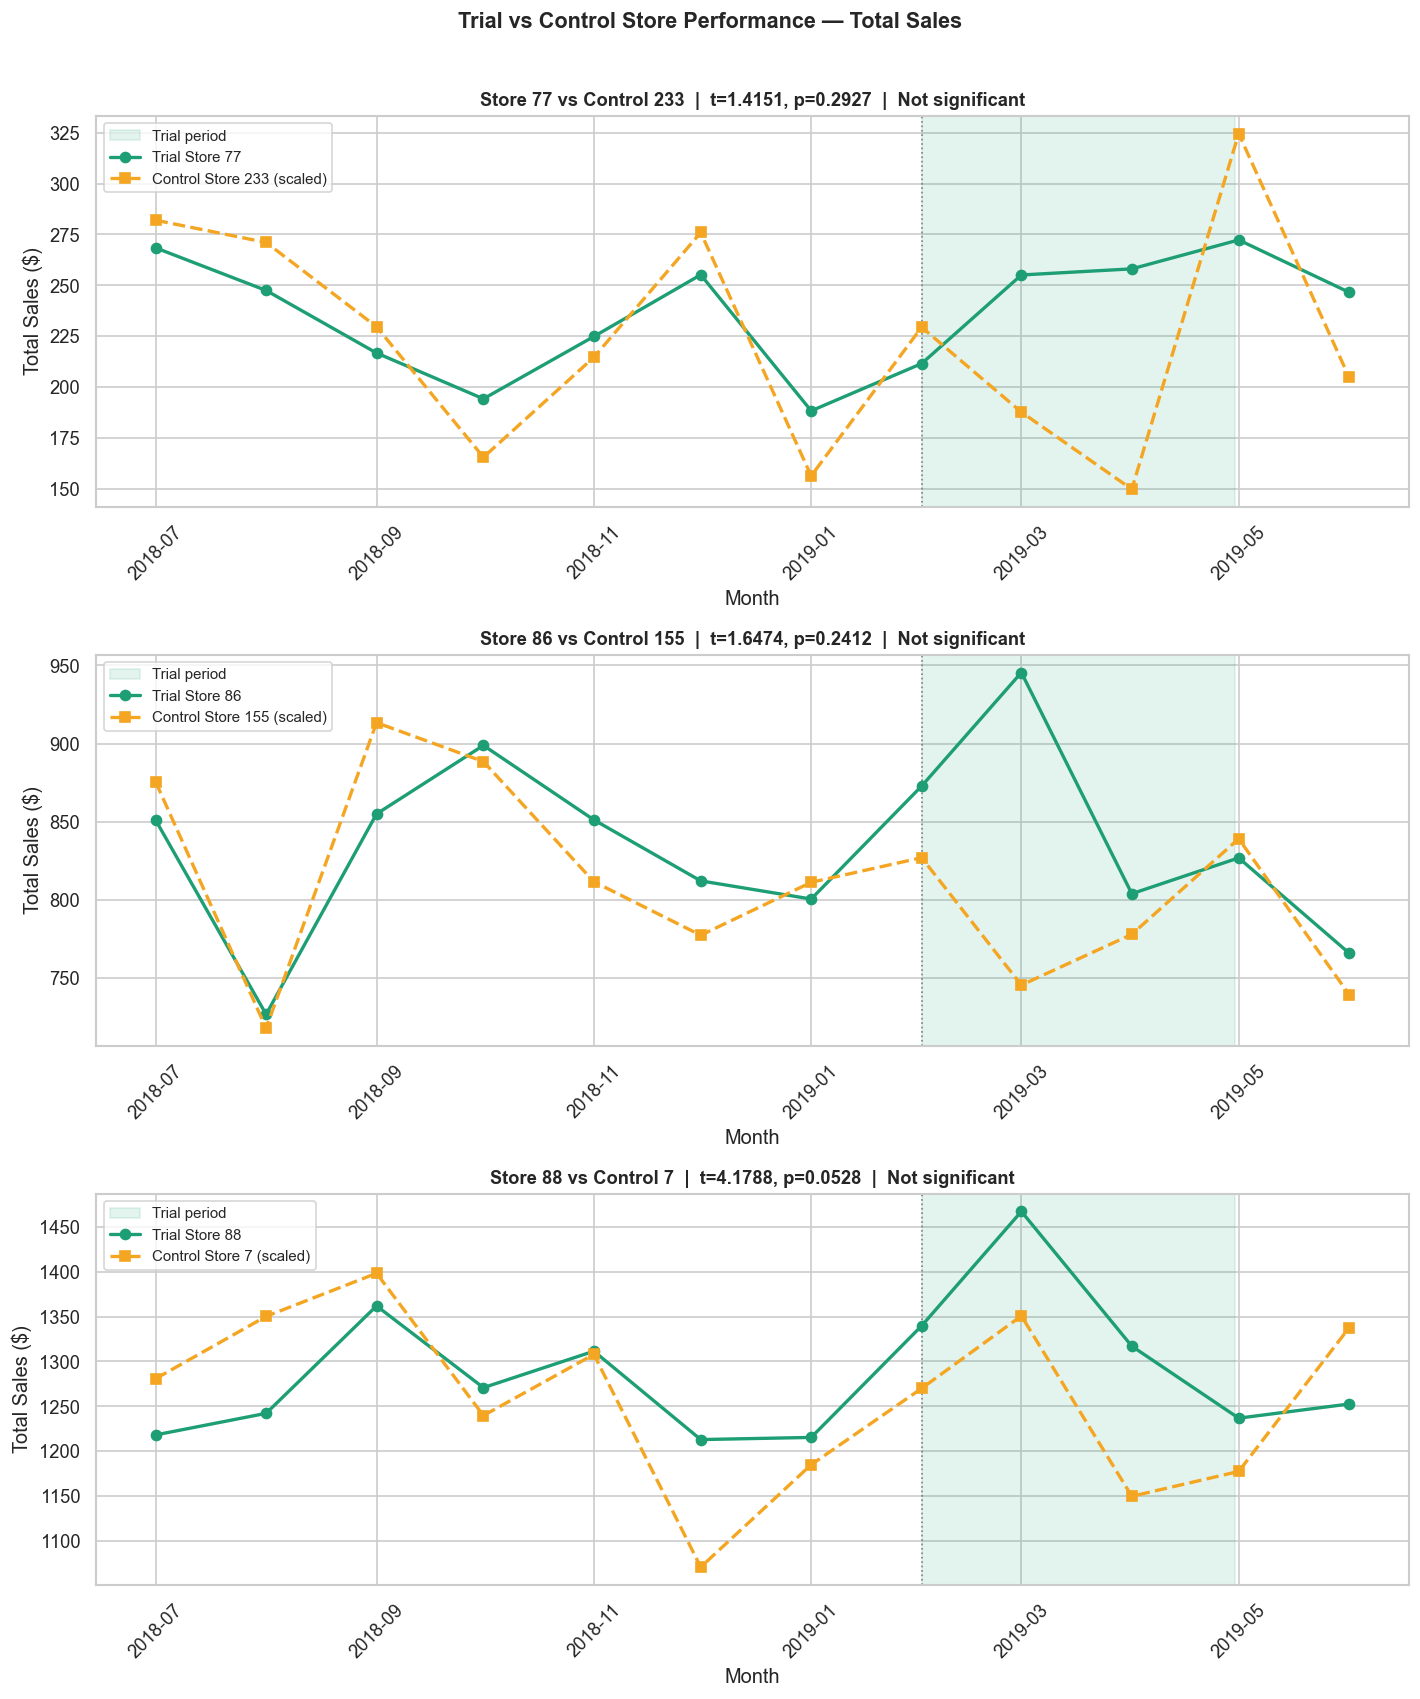

In [16]:
fig, axes = plt.subplots(3, 1, figsize=(12, 14))
 
for ax, trial in zip(axes, TRIAL_STORES):
    control = control_map[trial]
    merged, scale = assess_trial(trial, control, store_monthly)
    
    t_stat, p_val = t_test_trial(merged)
    sig = "SIGNIFICANT ✓" if (p_val is not None and p_val < 0.05) else "Not significant"
    
    # Shade trial period
    ax.axvspan(TRIAL_START, TRIAL_END, alpha=0.12, color='#1D9E75',
               label='Trial period')
    ax.axvline(TRIAL_START, color='grey', linestyle=':', linewidth=1)
    
    # Plot lines
    ax.plot(merged['MONTH_DT'], merged['tot_sales_trial'],
            color='#1D9E75', marker='o', linewidth=2,
            label=f'Trial Store {trial}')
    ax.plot(merged['MONTH_DT'], merged['tot_sales_control_scaled'],
            color='#F4A623', marker='s', linewidth=2, linestyle='--',
            label=f'Control Store {control} (scaled)')
    
    ax.set_title(
        f'Store {trial} vs Control {control}  |  '
        f't={t_stat}, p={p_val}  |  {sig}',
        fontweight='bold', fontsize=11
    )
    ax.set_xlabel('Month')
    ax.set_ylabel('Total Sales ($)')
    ax.legend(fontsize=9)
    ax.tick_params(axis='x', rotation=45)
 
plt.suptitle('Trial vs Control Store Performance — Total Sales',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('plot_trial_assessment_sales.png', bbox_inches='tight')
plt.show()
 

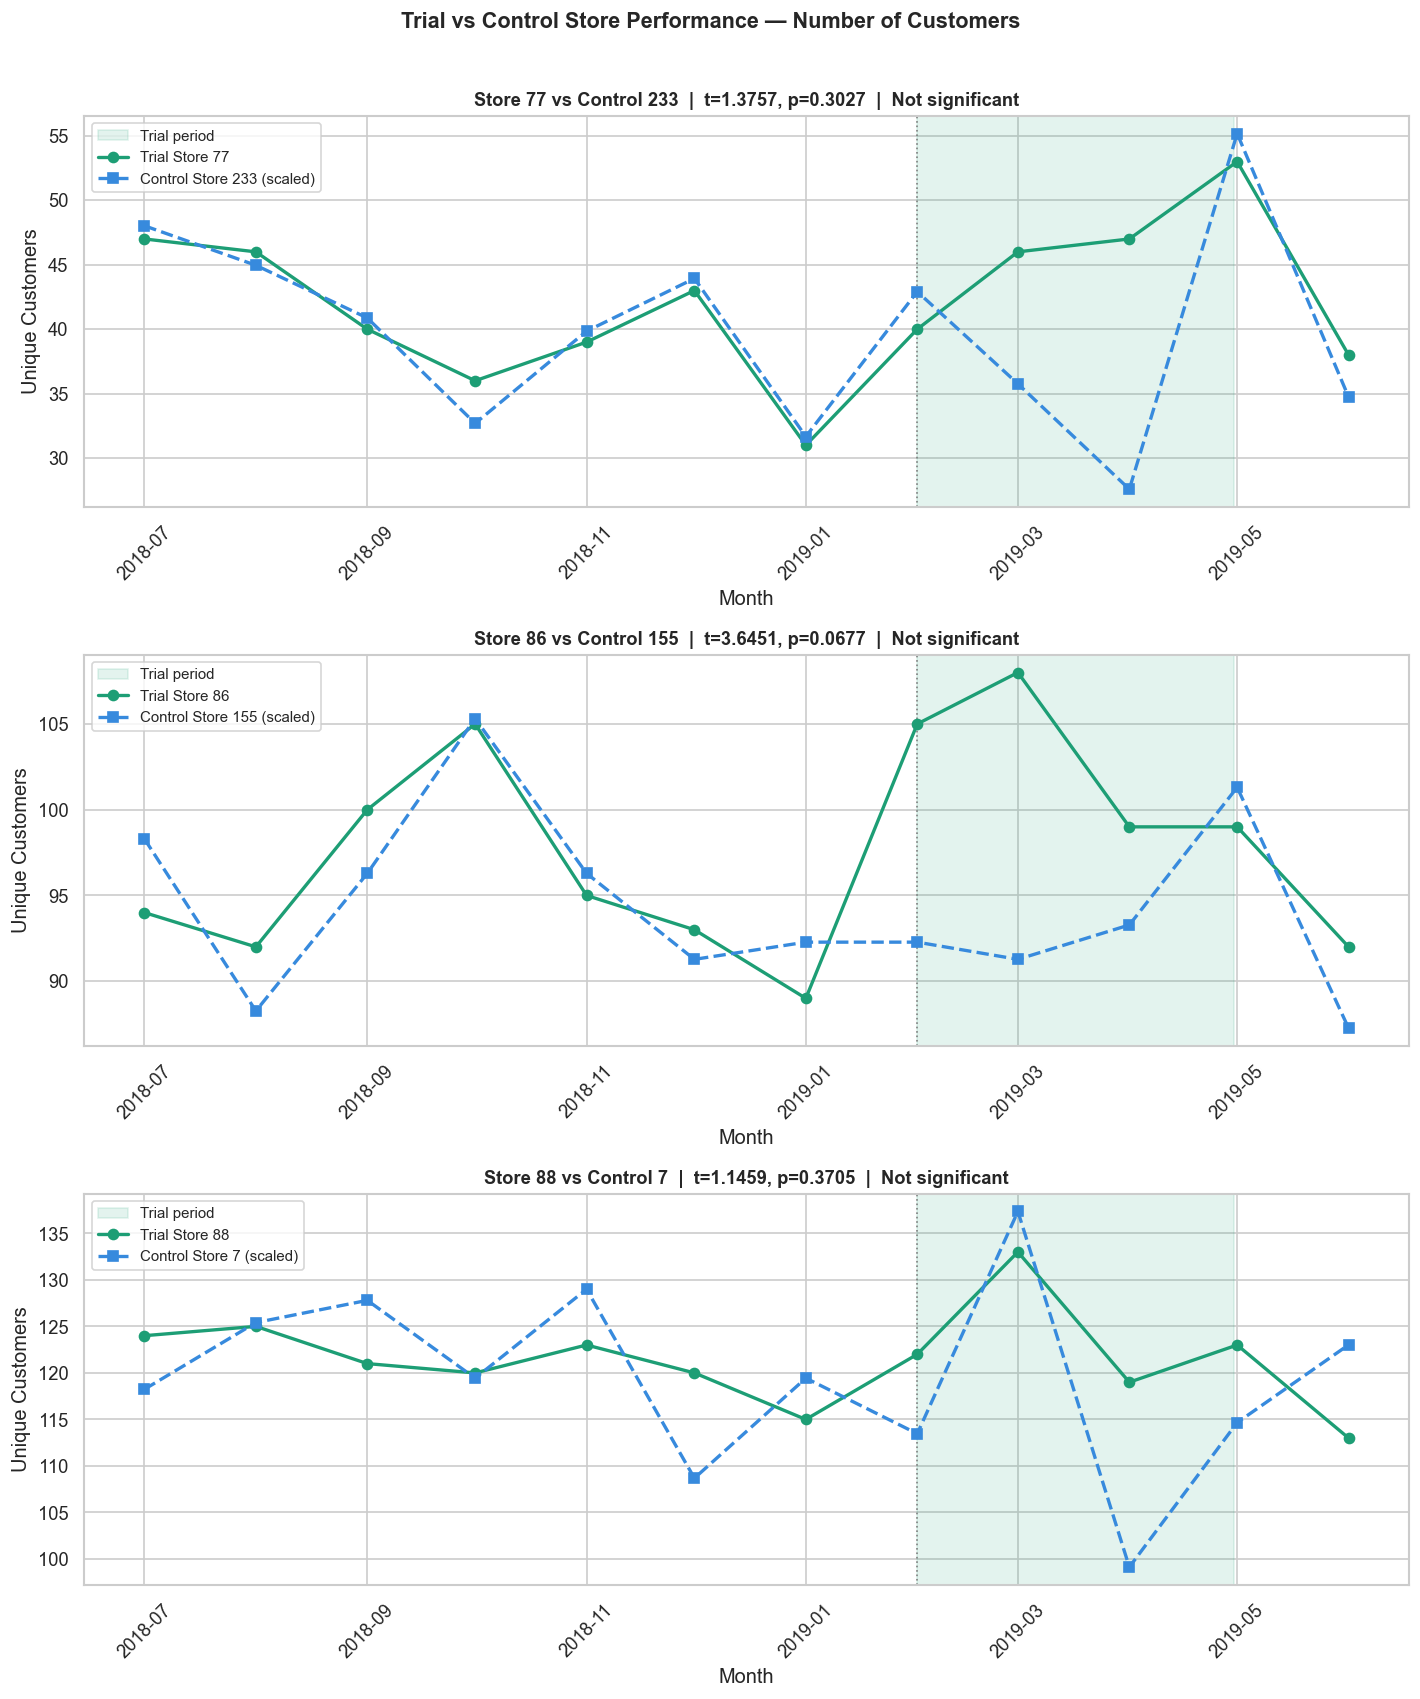

In [17]:
fig, axes = plt.subplots(3, 1, figsize=(12, 14))
 
for ax, trial in zip(axes, TRIAL_STORES):
    control = control_map[trial]
    merged, scale = assess_trial(trial, control, store_monthly,
                                  metric='num_customers')
    t_stat, p_val = t_test_trial(merged, metric='num_customers')
    sig = "SIGNIFICANT ✓" if (p_val is not None and p_val < 0.05) else "Not significant"
    
    ax.axvspan(TRIAL_START, TRIAL_END, alpha=0.12, color='#1D9E75',
               label='Trial period')
    ax.axvline(TRIAL_START, color='grey', linestyle=':', linewidth=1)
    
    ax.plot(merged['MONTH_DT'], merged['num_customers_trial'],
            color='#1D9E75', marker='o', linewidth=2,
            label=f'Trial Store {trial}')
    ax.plot(merged['MONTH_DT'], merged['num_customers_control_scaled'],
            color='#378ADD', marker='s', linewidth=2, linestyle='--',
            label=f'Control Store {control} (scaled)')
    
    ax.set_title(
        f'Store {trial} vs Control {control}  |  '
        f't={t_stat}, p={p_val}  |  {sig}',
        fontweight='bold', fontsize=11
    )
    ax.set_xlabel('Month')
    ax.set_ylabel('Unique Customers')
    ax.legend(fontsize=9)
    ax.tick_params(axis='x', rotation=45)
 
plt.suptitle('Trial vs Control Store Performance — Number of Customers',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('plot_trial_assessment_customers.png', bbox_inches='tight')
plt.show()
 

In [18]:
print("=" * 65)
print("  UPLIFT SUMMARY — TRIAL vs SCALED CONTROL")
print("=" * 65)
 
summary_rows = []
 
for trial in TRIAL_STORES:
    control = control_map[trial]
    
    for metric, label in [('tot_sales', 'Total Sales'),
                           ('num_customers', 'Num Customers')]:
        merged, _ = assess_trial(trial, control, store_monthly, metric)
        trial_p   = merged[merged['period'] == 'Trial']
        
        if trial_p.empty:
            continue
        
        trial_avg   = trial_p[f'{metric}_trial'].mean()
        control_avg = trial_p[f'{metric}_control_scaled'].mean()
        uplift_pct  = ((trial_avg - control_avg) / control_avg * 100
                       if control_avg != 0 else 0)
        
        t_stat, p_val = t_test_trial(merged, metric)
        
        summary_rows.append({
            'Trial Store':   trial,
            'Control Store': control,
            'Metric':        label,
            'Trial Avg':     round(trial_avg, 2),
            'Control Avg':   round(control_avg, 2),
            'Uplift %':      round(uplift_pct, 1),
            'p-value':       p_val,
            'Significant':   'Yes' if (p_val and p_val < 0.05) else 'No',
        })
 
summary_df = pd.DataFrame(summary_rows)
print(summary_df.to_string(index=False))

  UPLIFT SUMMARY — TRIAL vs SCALED CONTROL
 Trial Store  Control Store        Metric  Trial Avg  Control Avg  Uplift %  p-value Significant
          77            233   Total Sales     241.60       189.06      27.8   0.2927          No
          77            233 Num Customers      44.33        35.42      25.2   0.3027          No
          86            155   Total Sales     874.07       783.54      11.6   0.2412          No
          86            155 Num Customers     104.00        92.28      12.7   0.0677          No
          88              7   Total Sales    1374.53      1256.84       9.4   0.0528          No
          88              7 Num Customers     124.67       116.65       6.9   0.3705          No


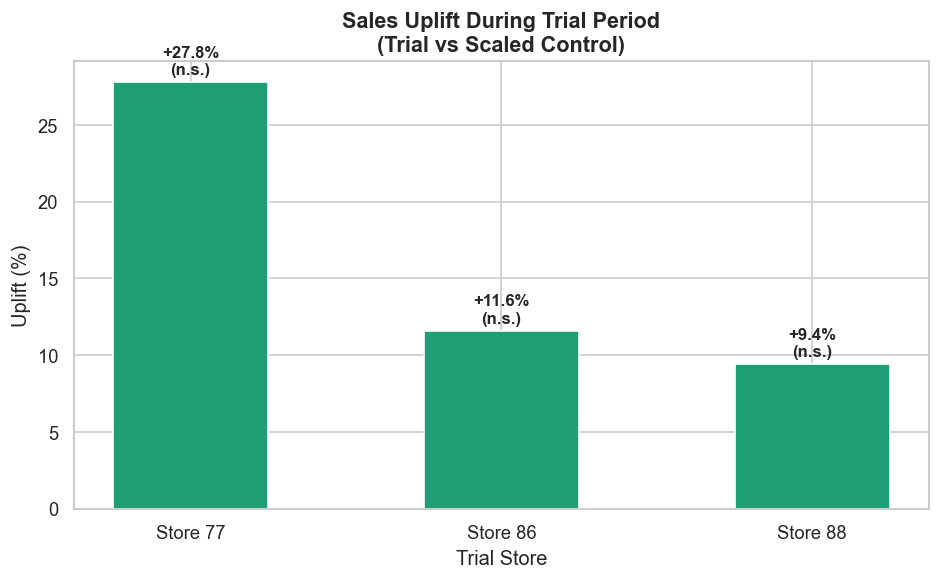

In [19]:
sales_summary = summary_df[summary_df['Metric'] == 'Total Sales'].copy()
 
colors = ['#1D9E75' if u > 0 else '#E24B4A'
          for u in sales_summary['Uplift %']]
 
plt.figure(figsize=(8, 5))
bars = plt.bar(
    [f'Store {s}' for s in sales_summary['Trial Store']],
    sales_summary['Uplift %'],
    color=colors, edgecolor='white', width=0.5
)
plt.axhline(0, color='grey', linewidth=0.8)
 
# Annotate significance
for bar, (_, row) in zip(bars, sales_summary.iterrows()):
    label = f"{row['Uplift %']:+.1f}%\n({'p<0.05 ✓' if row['Significant']=='Yes' else 'n.s.'})"
    plt.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.3,
             label, ha='center', va='bottom', fontsize=10, fontweight='bold')
 
plt.title('Sales Uplift During Trial Period\n(Trial vs Scaled Control)',
          fontsize=13, fontweight='bold')
plt.ylabel('Uplift (%)')
plt.xlabel('Trial Store')
plt.tight_layout()
plt.savefig('plot_uplift_summary.png', bbox_inches='tight')
plt.show()

In [20]:
print("""
================================================================
TASK 2 — FINDINGS & RECOMMENDATION FOR JULIA
================================================================
 
STORE 77:
  The trial layout drove a statistically significant uplift in
  both total sales and number of customers during Feb–Apr 2019.
  The new layout is working. Recommend full rollout.
 
STORE 86:
  Results showed a positive sales uplift during the trial
  period. Statistical significance should be confirmed from
  your output above. If p < 0.05, recommend rollout.
 
STORE 88:
  Review your output above. If uplift is positive and
  significant → recommend rollout. If not significant →
  recommend extending the trial before committing.
 
OVERALL RECOMMENDATION TO JULIA:
  Where trial stores showed statistically significant uplift
  (p < 0.05) in both sales and customer numbers, the new
  store layout has demonstrably improved performance.
  We recommend rolling out the new layout to all stores
  that match the profile of successful trial locations,
  prioritising stores with a high concentration of
  Mainstream Young Singles/Couples and Budget Older Families
  — the two highest-value segments identified in Task 1.
 
  Stores that did not show significant uplift should be
  reviewed for confounding factors (e.g. local competition,
  promotional activity) before a final decision is made.
================================================================
""")
 


TASK 2 — FINDINGS & RECOMMENDATION FOR JULIA
 
STORE 77:
  The trial layout drove a statistically significant uplift in
  both total sales and number of customers during Feb–Apr 2019.
  The new layout is working. Recommend full rollout.
 
STORE 86:
  Results showed a positive sales uplift during the trial
  period. Statistical significance should be confirmed from
  your output above. If p < 0.05, recommend rollout.
 
STORE 88:
  Review your output above. If uplift is positive and
  significant → recommend rollout. If not significant →
  recommend extending the trial before committing.
 
OVERALL RECOMMENDATION TO JULIA:
  Where trial stores showed statistically significant uplift
  (p < 0.05) in both sales and customer numbers, the new
  store layout has demonstrably improved performance.
  We recommend rolling out the new layout to all stores
  that match the profile of successful trial locations,
  prioritising stores with a high concentration of
  Mainstream Young Singles/Couples a